In [8]:
import pandas as pd  # For data manipulation
import numpy as np   # For numerical operations
import matplotlib.pyplot as plt  # For plotting
import seaborn as sns  # For advanced visualizations

sns.set(style="whitegrid")

In [9]:
file_path = 'Walmart_Sales.csv' 
data = pd.read_csv(file_path)

data.head()

,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,05-02-2010,1643690.90,0,42.31,2.572,211.096358,8.106
1,1,12-02-2010,1641957.44,1,38.51,2.548,211.242170,8.106
2,1,19-02-2010,1611968.17,0,39.93,2.514,211.289143,8.106
3,1,26-02-2010,1409727.59,0,46.63,2.561,211.319643,8.106
4,1,05-03-2010,1554806.68,0,46.50,2.625,211.350143,8.106


In [10]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6435 entries, 0 to 6434
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Store         6435 non-null   int64  
 1   Date          6435 non-null   object 
 2   Weekly_Sales  6435 non-null   float64
 3   Holiday_Flag  6435 non-null   int64  
 4   Temperature   6435 non-null   float64
 5   Fuel_Price    6435 non-null   float64
 6   CPI           6435 non-null   float64
 7   Unemployment  6435 non-null   float64
dtypes: float64(5), int64(2), object(1)
memory usage: 402.3+ KB


In [11]:
data.isnull().sum()

Store           0
Date            0
Weekly_Sales    0
Holiday_Flag    0
Temperature     0
Fuel_Price      0
CPI             0
Unemployment    0
dtype: int64

In [12]:
unique_counts = data.apply(pd.Series.nunique)
print(unique_counts)

Store             45
Date             143
Weekly_Sales    6435
Holiday_Flag       2
Temperature     3528
Fuel_Price       892
CPI             2145
Unemployment     349
dtype: int64


In [13]:
data.describe()

,Store,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
count,6435.000000,6.435000e+03,6435.000000,6435.000000,6435.000000,6435.000000,6435.000000
mean,23.000000,1.046965e+06,0.069930,60.663782,3.358607,171.578394,7.999151
std,12.988182,5.643666e+05,0.255049,18.444933,0.459020,39.356712,1.875885
min,1.000000,2.099862e+05,0.000000,-2.060000,2.472000,126.064000,3.879000
25%,12.000000,5.533501e+05,0.000000,47.460000,2.933000,131.735000,6.891000
50%,23.000000,9.607460e+05,0.000000,62.670000,3.445000,182.616521,7.874000
75%,34.000000,1.420159e+06,0.000000,74.940000,3.735000,212.743293,8.622000
max,45.000000,3.818686e+06,1.000000,100.140000,4.468000,227.232807,14.313000


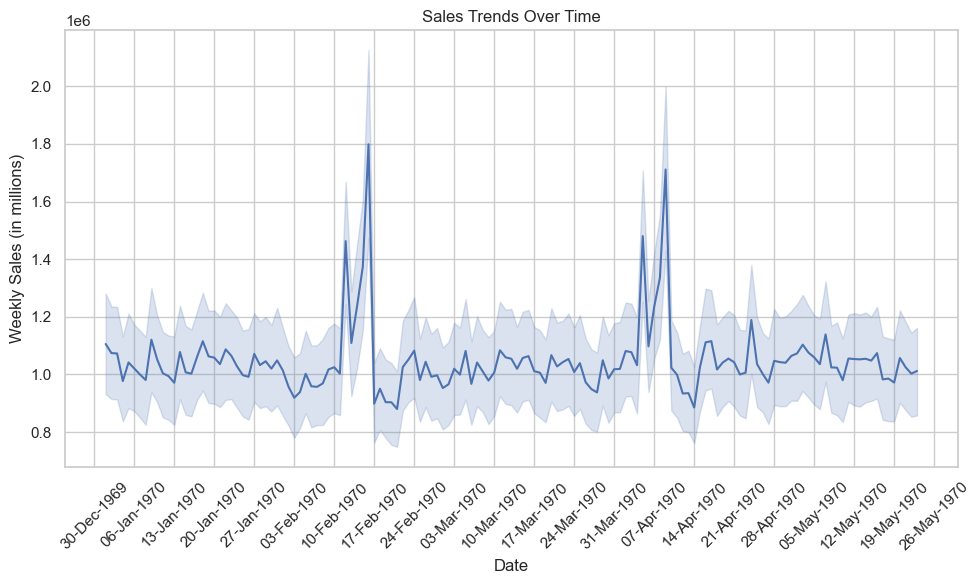

In [14]:
import matplotlib.dates as mdates

plt.figure(figsize=(10,6))
sns.lineplot(x='Date', y='Weekly_Sales', data=data)

plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%d-%b-%Y'))  # Display day, month, year

plt.gca().xaxis.set_major_locator(mdates.WeekdayLocator(interval=1))

plt.xticks(rotation=45)

plt.title('Sales Trends Over Time')
plt.xlabel('Date')
plt.ylabel('Weekly Sales (in millions)')

plt.tight_layout()
plt.show()

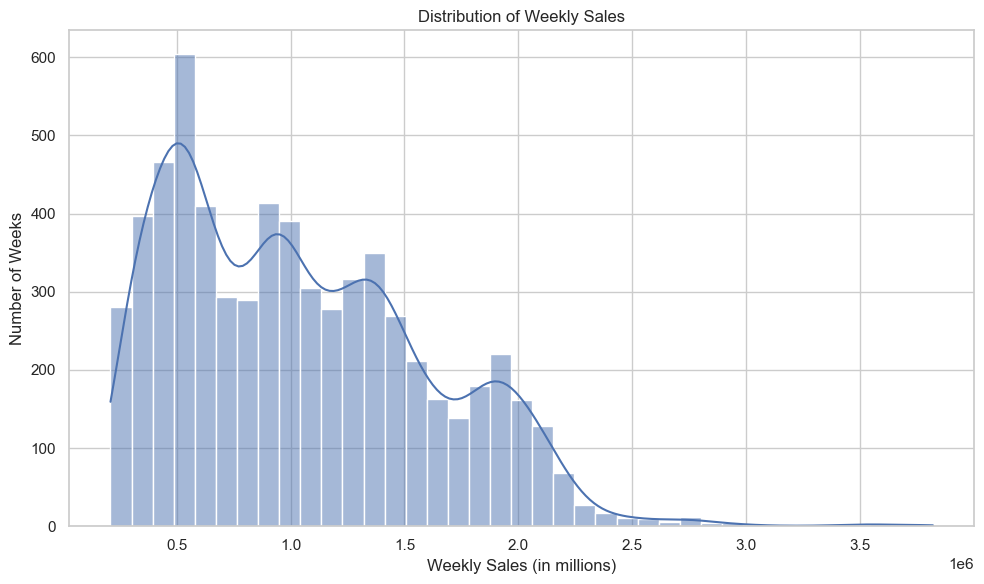

In [15]:
plt.figure(figsize=(10,6))
sns.histplot(data['Weekly_Sales'], kde=True)

# Add title and labels
plt.title('Distribution of Weekly Sales')
plt.xlabel('Weekly Sales (in millions)')  # Adjusted for clarity
plt.ylabel('Number of Weeks')

# Show the plot
plt.tight_layout()
plt.show()

In [16]:
aggregated_data = data.groupby(['Date', 'Store']).agg({'Weekly_Sales': 'sum'}).reset_index()

print(aggregated_data.head())

         Date  Store  Weekly_Sales
0  01-04-2011      1    1495064.75
1  01-04-2011      2    1800171.36
2  01-04-2011      3     374556.08
3  01-04-2011      4    1900246.47
4  01-04-2011      5     314316.55


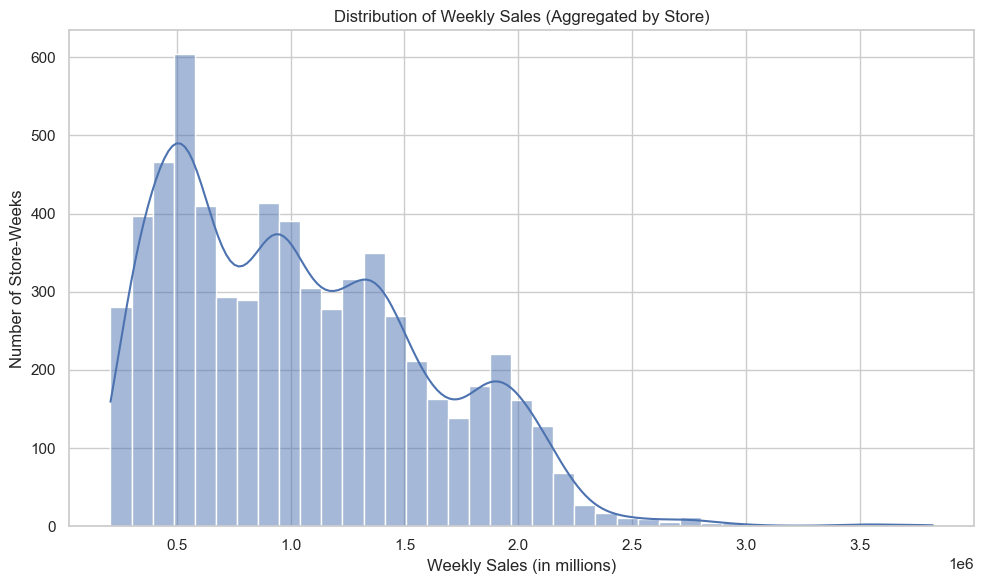

In [17]:
plt.figure(figsize=(10,6))
sns.histplot(aggregated_data['Weekly_Sales'], kde=True)

plt.title('Distribution of Weekly Sales (Aggregated by Store)')
plt.xlabel('Weekly Sales (in millions)')
plt.ylabel('Number of Store-Weeks')

plt.tight_layout()
plt.show()

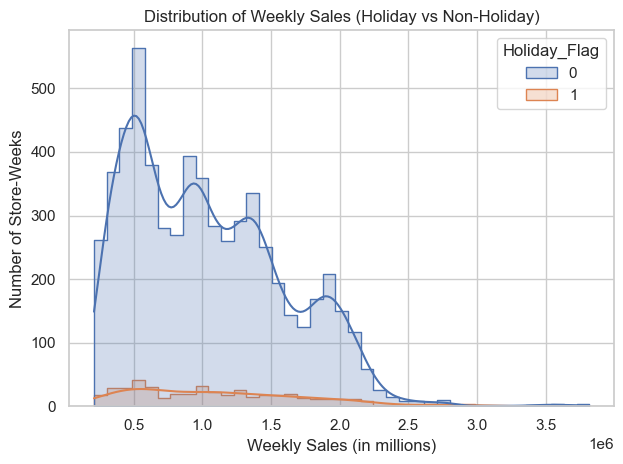

In [18]:
sns.histplot(data=data, x='Weekly_Sales', kde=True, hue='Holiday_Flag', element='step')
plt.title('Distribution of Weekly Sales (Holiday vs Non-Holiday)')
plt.xlabel('Weekly Sales (in millions)')
plt.ylabel('Number of Store-Weeks')
plt.tight_layout()
plt.show()

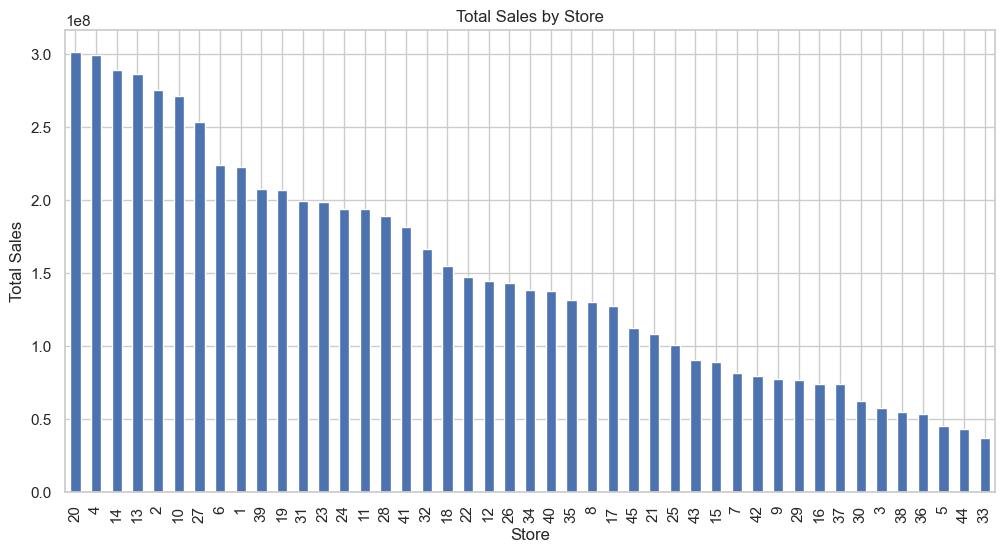

In [19]:
# Group by Store to analyze performance
store_sales = data.groupby('Store')['Weekly_Sales'].sum().sort_values(ascending=False)
store_sales.plot(kind='bar', figsize=(12, 6))
plt.title('Total Sales by Store')
plt.xlabel('Store')
plt.ylabel('Total Sales')
plt.show()

In [ ]:
#Observation: Stores 20, 4, and 14 are the top 3 performing stores, while Stores 33, 5, and 36 are among the lowest in terms of total sales.

In [ ]:
#numeric_data = data.select_dtypes(include=[np.number])  # Select only numeric columns

# Create the correlation matrix with only numeric columns
#plt.figure(figsize=(10, 8))
#sns.heatmap(numeric_data.corr(), annot=True, cmap='coolwarm')
#plt.title('Correlation Matrix of Numeric Features')
#plt.show()

In [20]:
#Lagged sales values are the strongest predictors, highlighting the importance of past sales in forecasting future sales. This makes temporal analysis or time series models very relevant.

In [21]:
#Investigate whether there is a relationship between temperature and sales. Use scatter plots or line plots to explore how sales vary with temperature changes.

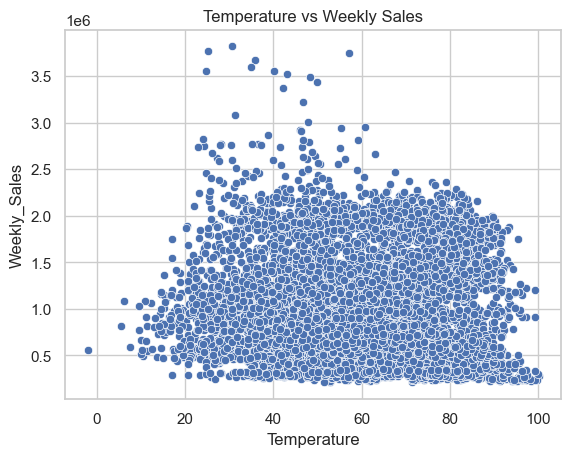

In [22]:
sns.scatterplot(x='Temperature', y='Weekly_Sales', data=data)
plt.title('Temperature vs Weekly Sales')
plt.show()

In [23]:
#Similarly, analyze the impact of fuel price fluctuations on sales. This might be more relevant for certain stores or time periods.

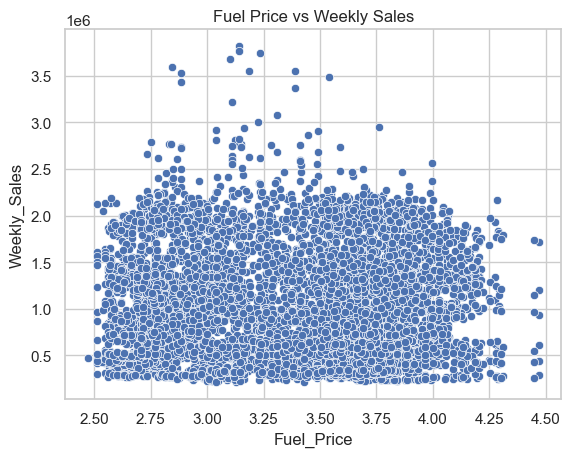

In [24]:
sns.scatterplot(x='Fuel_Price', y='Weekly_Sales', data=data)
plt.title('Fuel Price vs Weekly Sales')
plt.show()

In [25]:
#nvestigate whether unemployment has any significant correlation with sales. This might help explain dips or peaks in specific time periods.

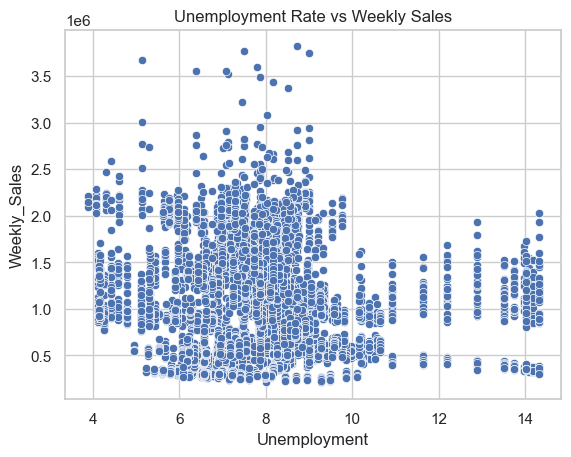

In [26]:
sns.scatterplot(x='Unemployment', y='Weekly_Sales', data=data)
plt.title('Unemployment Rate vs Weekly Sales')
plt.show()

In [27]:
#Run a t-test to determine whether there is a statistically significant difference in weekly sales between holiday and non-holiday weeks.

In [28]:
from scipy.stats import ttest_ind

# Split sales data into holiday and non-holiday weeks
holiday_sales = data[data['Holiday_Flag'] == 1]['Weekly_Sales']
non_holiday_sales = data[data['Holiday_Flag'] == 0]['Weekly_Sales']

# Perform t-test
t_stat, p_val = ttest_ind(holiday_sales, non_holiday_sales)
print(f"T-statistic: {t_stat}, P-value: {p_val}")

T-statistic: 2.9608919093259036, P-value: 0.003078699263818616


In [29]:
#Observation: The p-value indicates a statistically significant difference between holiday and non-holiday weeks.

In [30]:
#lag variables (e.g., Sales_Lag1, Sales_Lag2) to account for the sales trend in the previous weeks.

In [31]:
data['Sales_Lag1'] = data['Weekly_Sales'].shift(1)
data['Sales_Lag2'] = data['Weekly_Sales'].shift(2)

In [32]:
#Calculate rolling averages to smooth out short-term fluctuations.

In [33]:
data['Rolling_Mean_4'] = data['Weekly_Sales'].rolling(window=4).mean()  # 4-week rolling average

In [34]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

# Define the features and target variable
X = data[['Temperature', 'Fuel_Price', 'CPI', 'Unemployment', 'Holiday_Flag']]
y = data['Weekly_Sales']

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Build and train the model
model = LinearRegression()
model.fit(X_train, y_train)

# Predict and evaluate
y_pred = model.predict(X_test)

In [35]:
from sklearn.ensemble import RandomForestRegressor

# Initialize and train the model
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# Predict and evaluate
rf_pred = rf_model.predict(X_test)

In [36]:
#RMSE (Root Mean Squared Error): Measures how well the model predicts sales.
#MAE (Mean Absolute Error): Good for interpreting average prediction error in the same units as Weekly_Sales.
#R² (R-squared): Measures how much of the variance in Weekly_Sales is explained by your model.

In [37]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Calculate metrics
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"RMSE: {rmse}")
print(f"MAE: {mae}")
print(f"R-squared: {r2}")

RMSE: 562631.7724810028
MAE: 475432.53295882524
R-squared: 0.01738312550370069


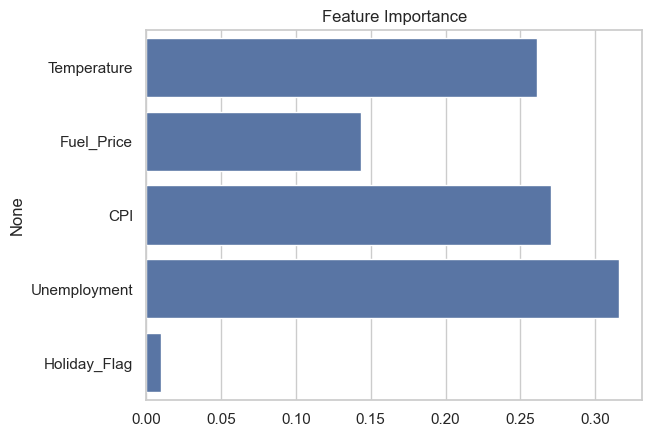

In [38]:
feature_importance = rf_model.feature_importances_
sns.barplot(x=feature_importance, y=X.columns)
plt.title('Feature Importance')
plt.show()

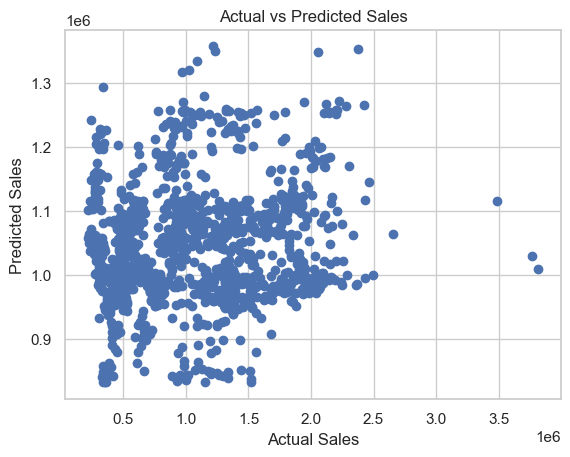

In [39]:
plt.scatter(y_test, y_pred)
plt.xlabel('Actual Sales')
plt.ylabel('Predicted Sales')
plt.title('Actual vs Predicted Sales')
plt.show()

In [40]:
#Possible Analysis:
#	•	Seasonality Analysis: Investigate if certain months or weeks have recurring sales patterns.
#	•	Impact of External Factors: Look at the correlation of external factors (temperature, fuel prices) with sales during specific weeks.
#	•	Store Performance: Identify the top 5 stores and analyze what sets them apart from underperforming stores.

In [41]:
from sklearn.model_selection import GridSearchCV

# Define the parameter grid
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [10, 20, 30],
    'min_samples_split': [2, 5, 10]
}

# Set up GridSearchCV
grid_search = GridSearchCV(estimator=rf_model, param_grid=param_grid, cv=3, n_jobs=-1, scoring='neg_mean_squared_error')
grid_search.fit(X_train, y_train)

# Print best parameters
print("Best Parameters:", grid_search.best_params_)

Best Parameters: {'max_depth': 10, 'min_samples_split': 10, 'n_estimators': 300}


In [42]:
# Build the optimized Random Forest model
optimized_rf_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=10,
    min_samples_split=10,
    random_state=42
)

# Fit the optimized model
optimized_rf_model.fit(X_train, y_train)

# Predict on the test set
optimized_y_pred = optimized_rf_model.predict(X_test)

# Evaluate the optimized model
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

rmse_opt = np.sqrt(mean_squared_error(y_test, optimized_y_pred))
mae_opt = mean_absolute_error(y_test, optimized_y_pred)
r2_opt = r2_score(y_test, optimized_y_pred)

print(f"Optimized RMSE: {rmse_opt}")
print(f"Optimized MAE: {mae_opt}")
print(f"Optimized R-squared: {r2_opt}")

Optimized RMSE: 477330.2777497797
Optimized MAE: 371283.68012287834
Optimized R-squared: 0.29274882596891216


In [43]:
# Add more lag features
data['Sales_Lag3'] = data['Weekly_Sales'].shift(3)
data['Sales_Lag4'] = data['Weekly_Sales'].shift(4)

# Add more rolling averages
data['Rolling_Mean_8'] = data['Weekly_Sales'].rolling(window=8).mean()
data['Rolling_Std_8'] = data['Weekly_Sales'].rolling(window=8).std()

In [44]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Assuming 'data' is your original dataset
# Step 1: Calculate the mean and standard deviation of Weekly_Sales
mean_sales = data['Weekly_Sales'].mean()
std_sales = data['Weekly_Sales'].std()

print(f"Mean Weekly Sales: {mean_sales}")
print(f"Standard Deviation of Weekly Sales: {std_sales}")

# Step 2: Create a baseline model that predicts the mean for every value
baseline_predictions = np.full_like(data['Weekly_Sales'], mean_sales)

# Step 3: Calculate RMSE, MAE, and R-squared for the baseline model
baseline_rmse = np.sqrt(mean_squared_error(data['Weekly_Sales'], baseline_predictions))
baseline_mae = mean_absolute_error(data['Weekly_Sales'], baseline_predictions)
baseline_r2 = r2_score(data['Weekly_Sales'], baseline_predictions)

print(f"Baseline RMSE: {baseline_rmse}")
print(f"Baseline MAE: {baseline_mae}")
print(f"Baseline R-Squared: {baseline_r2}")

# Step 4: Calculate the "optimal" RMSE and MAE based on minimum achievable values
# - Minimum RMSE: Ideally should approach 0, but realistically limited by the standard deviation
min_rmse = std_sales  # Using standard deviation as the lower limit for RMSE
min_mae = std_sales / np.sqrt(2)  # MAE is typically lower than RMSE by a factor of sqrt(2)

# Hypothetical R-Squared: Best achievable R-squared should approach 1 (if no error)
hypothetical_r2 = 1.0  # Maximum R-squared for a perfect model

print(f"Optimal (Minimum) RMSE: {min_rmse:.2f}")
print(f"Optimal (Minimum) MAE: {min_mae:.2f}")
print(f"Optimal R-Squared: {hypothetical_r2}")

Mean Weekly Sales: 1046964.8775617715
Standard Deviation of Weekly Sales: 564366.6220536975
Baseline RMSE: 564322.7690195543
Baseline MAE: 469018.8574863543
Baseline R-Squared: 0.0
Optimal (Minimum) RMSE: 564366.62
Optimal (Minimum) MAE: 399067.47
Optimal R-Squared: 1.0


In [46]:
print(data.columns)

Index(['Store', 'Date', 'Weekly_Sales', 'Holiday_Flag', 'Temperature',
       'Fuel_Price', 'CPI', 'Unemployment', 'Sales_Lag1', 'Sales_Lag2',
       'Rolling_Mean_4', 'Sales_Lag3', 'Sales_Lag4', 'Rolling_Mean_8',
       'Rolling_Std_8'],
      dtype='object')


In [48]:
print(data.head())

   Store        Date  Weekly_Sales  Holiday_Flag  Temperature  Fuel_Price  \
0      1  05-02-2010    1643690.90             0        42.31       2.572   
1      1  12-02-2010    1641957.44             1        38.51       2.548   
2      1  19-02-2010    1611968.17             0        39.93       2.514   
3      1  26-02-2010    1409727.59             0        46.63       2.561   
4      1  05-03-2010    1554806.68             0        46.50       2.625   

          CPI  Unemployment  Sales_Lag1  Sales_Lag2  Rolling_Mean_4  \
0  211.096358         8.106         NaN         NaN             NaN   
1  211.242170         8.106  1643690.90         NaN             NaN   
2  211.289143         8.106  1641957.44  1643690.90             NaN   
3  211.319643         8.106  1611968.17  1641957.44     1576836.025   
4  211.350143         8.106  1409727.59  1611968.17     1554614.970   

   Sales_Lag3  Sales_Lag4  Rolling_Mean_8  Rolling_Std_8  
0         NaN         NaN             NaN          

In [49]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6435 entries, 0 to 6434
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Store           6435 non-null   int64  
 1   Date            6435 non-null   object 
 2   Weekly_Sales    6435 non-null   float64
 3   Holiday_Flag    6435 non-null   int64  
 4   Temperature     6435 non-null   float64
 5   Fuel_Price      6435 non-null   float64
 6   CPI             6435 non-null   float64
 7   Unemployment    6435 non-null   float64
 8   Sales_Lag1      6434 non-null   float64
 9   Sales_Lag2      6433 non-null   float64
 10  Rolling_Mean_4  6432 non-null   float64
 11  Sales_Lag3      6432 non-null   float64
 12  Sales_Lag4      6431 non-null   float64
 13  Rolling_Mean_8  6428 non-null   float64
 14  Rolling_Std_8   6428 non-null   float64
dtypes: float64(12), int64(2), object(1)
memory usage: 754.2+ KB


In [50]:
data['Date'] = pd.to_datetime(data['Date'], format='%d-%m-%Y')

In [57]:
print(data.columns)

Index(['Store', 'Date', 'Weekly_Sales', 'Holiday_Flag', 'Temperature',
       'Fuel_Price', 'CPI', 'Unemployment', 'Sales_Lag1', 'Sales_Lag2',
       'Rolling_Mean_4', 'Sales_Lag3', 'Sales_Lag4', 'Rolling_Mean_8',
       'Rolling_Std_8'],
      dtype='object')


In [58]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6435 entries, 0 to 6434
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Store           6435 non-null   int64         
 1   Date            6435 non-null   datetime64[ns]
 2   Weekly_Sales    6435 non-null   float64       
 3   Holiday_Flag    6435 non-null   int64         
 4   Temperature     6435 non-null   float64       
 5   Fuel_Price      6435 non-null   float64       
 6   CPI             6435 non-null   float64       
 7   Unemployment    6435 non-null   float64       
 8   Sales_Lag1      6434 non-null   float64       
 9   Sales_Lag2      6433 non-null   float64       
 10  Rolling_Mean_4  6432 non-null   float64       
 11  Sales_Lag3      6432 non-null   float64       
 12  Sales_Lag4      6431 non-null   float64       
 13  Rolling_Mean_8  6428 non-null   float64       
 14  Rolling_Std_8   6428 non-null   float64       
dtypes: d

In [59]:
# Set the 'Date' column as the index and sort by date
sarima_data = data.copy()  # Create a copy to preserve original
sarima_data.set_index('Date', inplace=True)
sarima_data.sort_index(inplace=True)
print(sarima_data.head())  # Confirm that 'Date' is set as the index

            Store  Weekly_Sales  Holiday_Flag  Temperature  Fuel_Price  \
Date                                                                     
2010-02-05      1    1643690.90             0        42.31       2.572   
2010-02-05     10    2193048.75             0        54.34       2.962   
2010-02-05     37     536006.73             0        45.97       2.572   
2010-02-05     17     789036.02             0        23.11       2.666   
2010-02-05     30     465108.52             0        39.05       2.572   

                   CPI  Unemployment  Sales_Lag1  Sales_Lag2  Rolling_Mean_4  \
Date                                                                           
2010-02-05  211.096358         8.106         NaN         NaN             NaN   
2010-02-05  126.442065         9.765   549731.49   542009.46      960813.625   
2010-02-05  209.852966         8.554   272489.41   287360.05      349023.260   
2010-02-05  126.442065         6.548   475770.14   577198.97      583455.580   
2

/var/folders/8q/l0qtghqx10164m5gnknm_hxr0000gn/T/ipykernel_92842/2926072846.py:19: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  sarima_model = SARIMAX(aggregated_data['Weekly_Sales'].fillna(method='ffill'),  # Fill any missing values
/opt/homebrew/lib/python3.11/site-packages/statsmodels/tsa/statespace/sarimax.py:866: UserWarning: Too few observations to estimate starting parameters for ARMA and trend. All parameters except for variances will be set to zeros.
  warn('Too few observations to estimate starting parameters%s.'
/opt/homebrew/lib/python3.11/site-packages/statsmodels/tsa/statespace/sarimax.py:866: UserWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  warn('Too few observations to estimate starting parameters%s.'


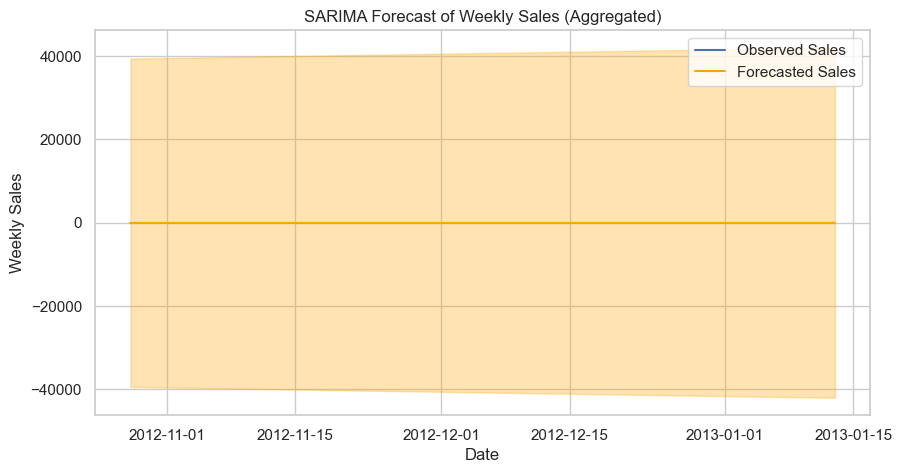

In [62]:
#DOES NOT WORK


import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX
import pandas as pd

sarima_data = data.copy()

sarima_data['Date'] = pd.to_datetime(sarima_data['Date'], format='%d-%m-%Y')

aggregated_data = sarima_data.groupby('Date')['Weekly_Sales'].sum().reset_index()

aggregated_data.set_index('Date', inplace=True)
aggregated_data = aggregated_data.asfreq('W')  # Setting frequency to weekly to match the sales data

sarima_model = SARIMAX(aggregated_data['Weekly_Sales'].fillna(method='ffill'),  # Fill any missing values
                       order=(2, 1, 2), seasonal_order=(1, 1, 1, 52))
sarima_results = sarima_model.fit(disp=False)

forecast = sarima_results.get_forecast(steps=12)
forecast_df = forecast.summary_frame()

forecast_index = pd.date_range(start=aggregated_data.index[-1] + pd.Timedelta(weeks=1), periods=12, freq='W')
forecast_df.index = forecast_index

plt.figure(figsize=(10, 5))
plt.plot(aggregated_data.index, aggregated_data['Weekly_Sales'], label='Observed Sales')
plt.plot(forecast_df.index, forecast_df['mean'], label='Forecasted Sales', color='orange')
plt.fill_between(forecast_df.index, forecast_df['mean_ci_lower'], forecast_df['mean_ci_upper'], color='orange', alpha=0.3)
plt.xlabel('Date')
plt.ylabel('Weekly Sales')
plt.title('SARIMA Forecast of Weekly Sales (Aggregated)')
plt.legend()
plt.show()